## Simulation (Fixed relative strike grid)

This notebook computes historic time series for implied vols, fitting error, DLV vs a gixed NMS grid.



In [1]:
%load_ext autoreload
%autoreload 1

#%aimport quantdata
#%aimport quantdata.biz_calendar
#%aimport quantdata.widb
#%aimport quantdata.widb.client
#%aimport quantdata.widb.day
#%aimport quantdata.widb.arbfree
#%aimport quantdata.widb.options_filter
#%aimport quantdata.utils.backbone
#%aimport quantdata.sanos.sanos_tools
#%aimport quantdata.sanos.arbfree
#%aimport quantdata.sanos.sanos
#%aimport quantdata.dysanos
%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_pricer
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 
%aimport quantdata.dysanos.grid.torch_simulator
%aimport quantdata.dysanos.grid.torch_universe
%aimport quantdata.dysanos.grid.torch_drift_change

from quantdata.dysanos.grid.torch_market import GridMarketDefinition, DateRange, PoolConfig, Context, date, GridConfig

grid_config     = GridConfig(grid_num_strikes=100)
grid_market_def = GridMarketDefinition( ticker="SPX", date_range=DateRange(start=date(2020, 1, 1), end=date(2025, 8, 30)), grid_config=grid_config )
market          = grid_market_def.load( pool_config = PoolConfig(num_workers=4, threading=False ), override_cache_mode="cacheonly", verbose=Context.all )
print(f"nms /done - found {len(market['dates'])} dates.")
    

nms /done - found 1412 dates.


00: Training ac_state20 version 0.2 group 'sm25_100' for 100000 epochs on SPX for date range 2020-01-01_2025-08-30x
00: Using batches of 400 samples with learning rate 0.0001 and weight decay 0.0001.
01:   Model config: ac_state20@sm25_100 0.2 0.25-smooth nms=20,(-2.00,1.00) state=20@FF(d=2,w=100,a=SELU,b=True) dlv=(0.01,3.00),fvol=(0.01,2.00) sample,mvsq=0.0001
01:   Grid config: nms,rg=(-2,1),nm=100,xp=(2.0,4.9,9.9,19.8,39.5,126.0,252.0);sth=0.25,mid=0.01,mxd=2,msqv=0.0001
01:   Mk Arb Free pre-processor: surface,mhs=0.0001,mw=0.10,mav=0.05,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
00: Instantiating ac_state20 version 0.2 on Env(prec=32,device=cpu,debug=False)... done; this took 0.11s.
00: Found existing recovery checkpoint 'C:/users/public/.dysanos_grid/sm25_100/ac_state20 15353129.pt'

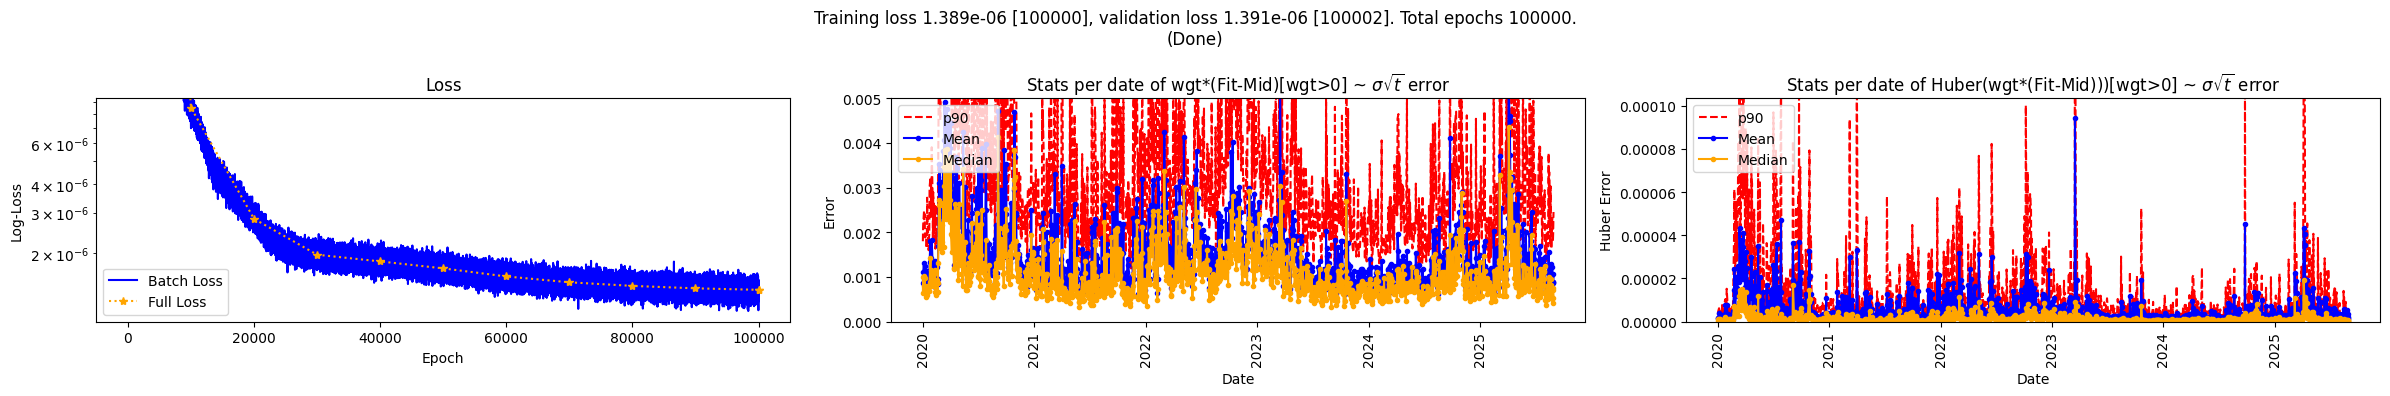

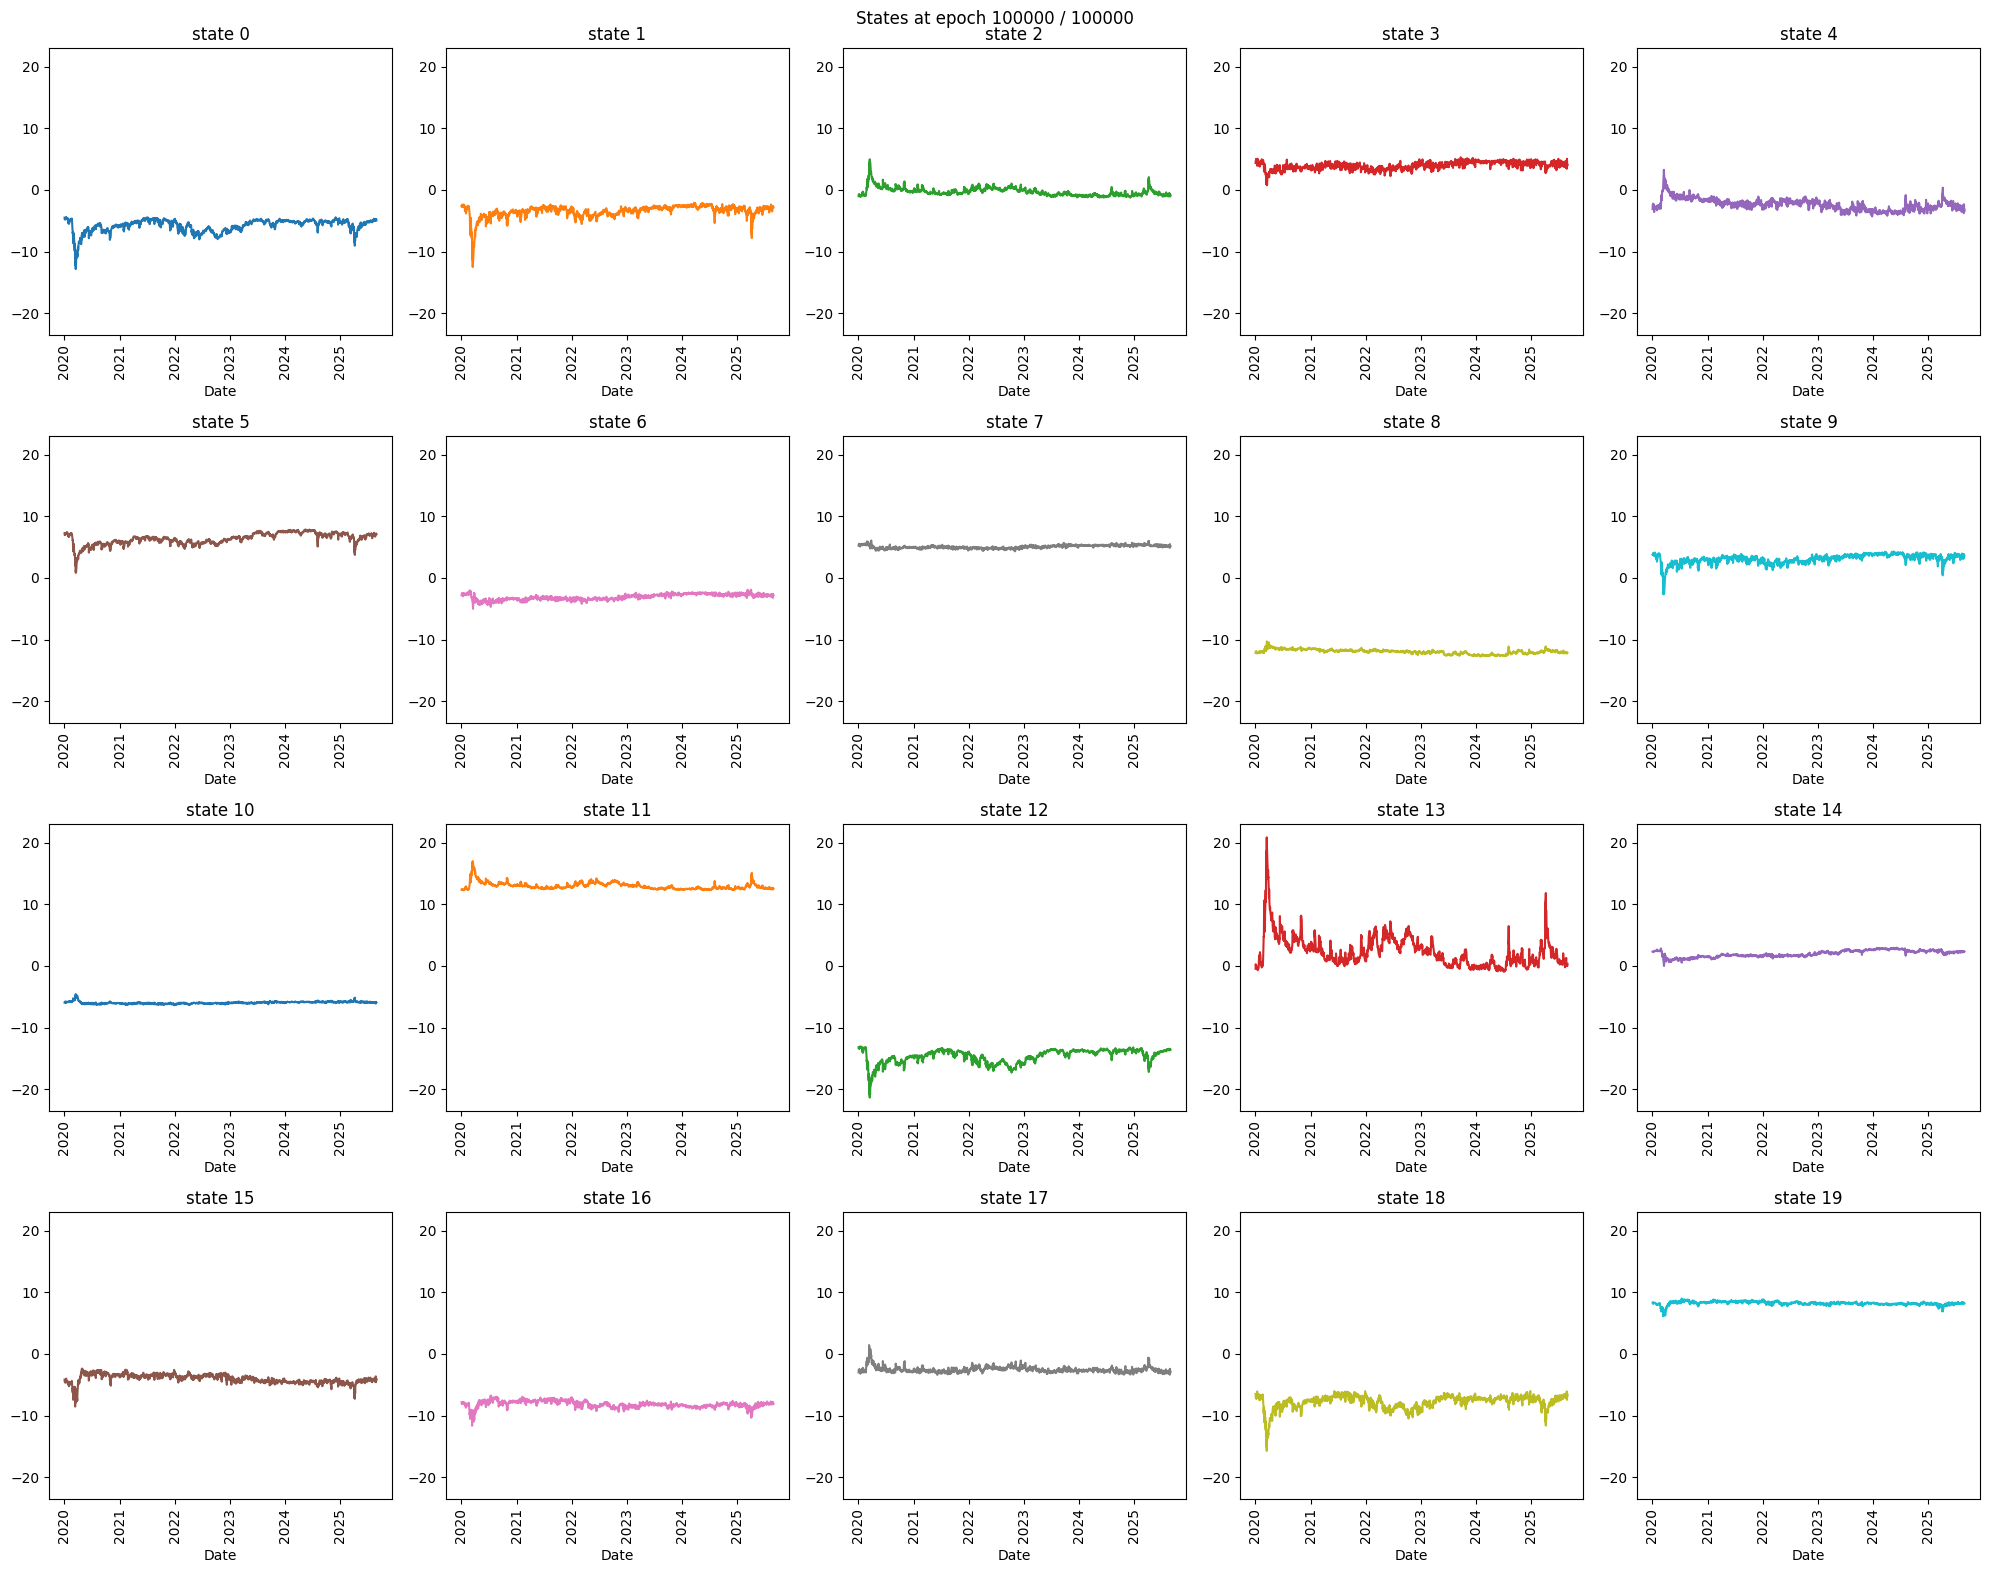

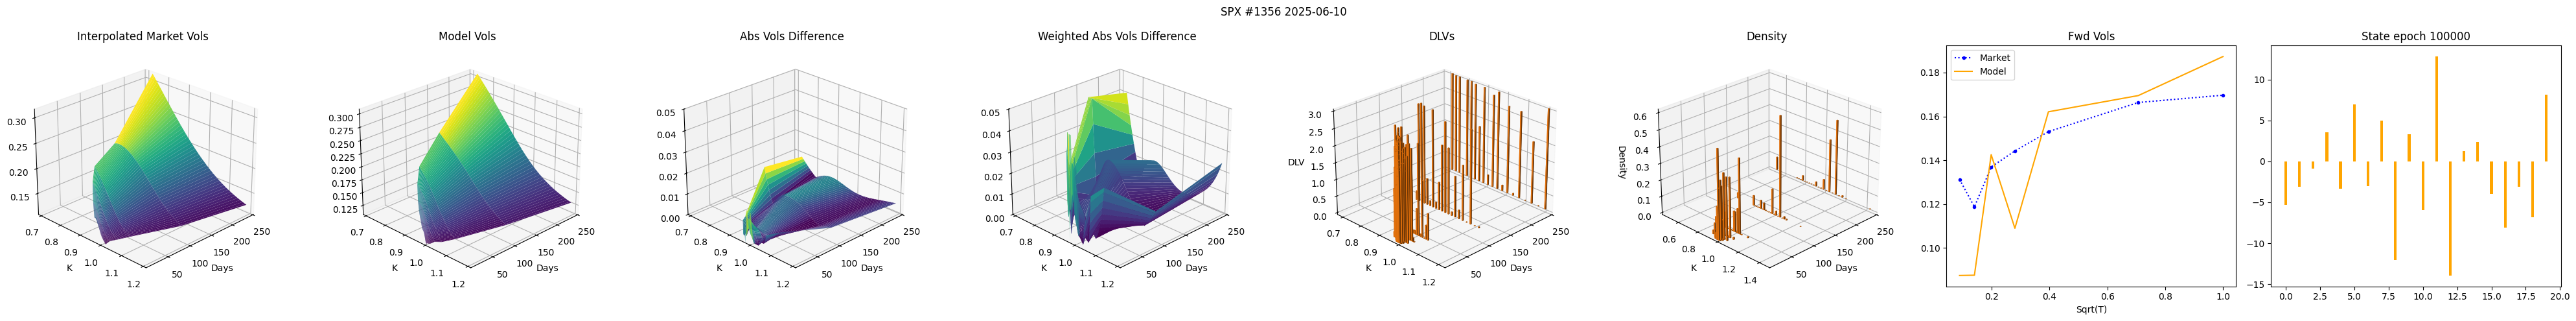

c:\Users\Public\venv\vqdata\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


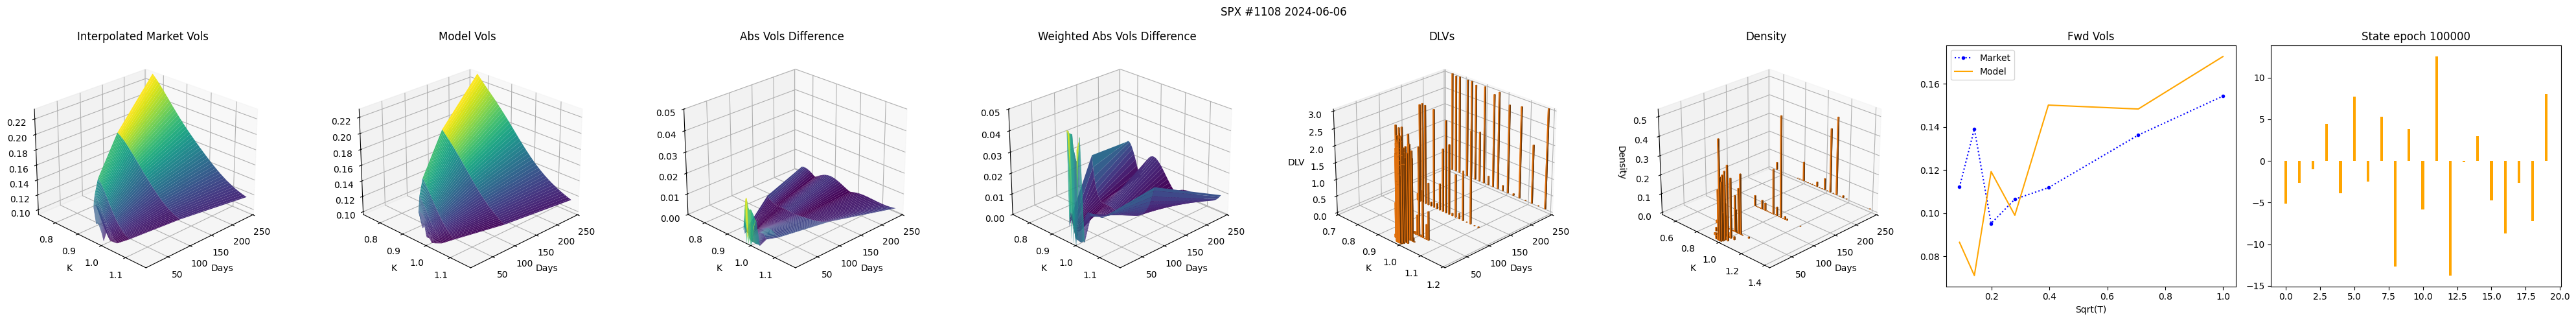

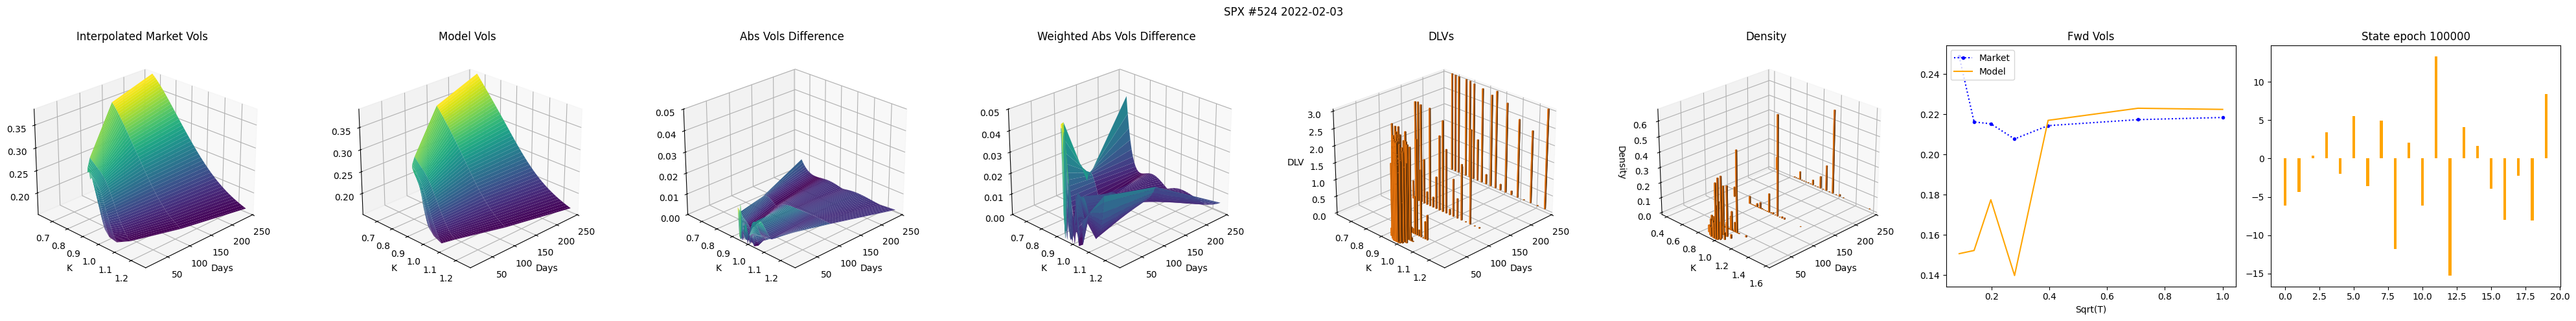

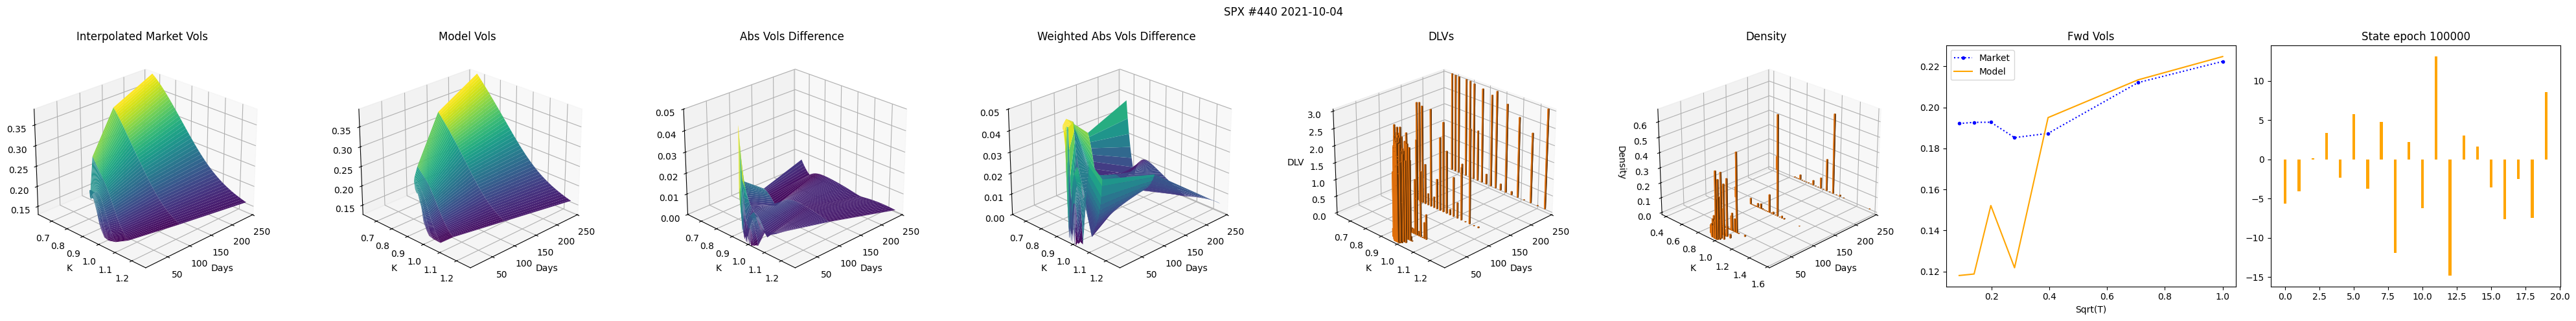

01:   Model checkpoint file is'C:/users/public/.dysanos_grid/sm25_100/ac_state20 15353129.pt'.
01:   Writing model output to 'C:/users/public/.dysanos_grid/sm25_100/ac_state20 15353129.mo'... done; this took 0.019s.
00: Model ac_state20 version 0.2 group 'sm25_100' trained for 100000 epochs. Final training loss: 1.389e-06, valuation loss: 1.391e-06. This took 0.021s.
/done


In [2]:
from cdxcore.dynaplot import FigStore, colors_tableau, figure, m_o_m
from quantdata.pool import PoolConfig
from quantdata.dysanos.grid.torch_gfx import VizConfig
from quantdata.dysanos.grid.torch_train import train, TrainConfig
from quantdata.dysanos.grid.torch_model import BaseEnvironment, FeedForward, SanosModel, SanosModelConfig, SanosDecoderConfig
import numpy as np

mdl_config = SanosModelConfig( 
    label="ac_state20",
    user_version="0.2",
    group="sm25_100",
    encoder_config = FeedForward.Config(
            activation = "SELU",
            num_depth = 2,
            num_width = 100,
            use_bias = True,
        ),
    decoder_config = SanosDecoderConfig(
        smoothness = 0.25,
        num_state = 20, 
        nn_config = FeedForward.Config(
            activation = "SELU",
            num_depth = 2,
            num_width = 100,
            use_bias = True,
        ),
    ),
)

env          = BaseEnvironment(device="cpu", debug=False)
viz_config   = VizConfig( num_viz_dates=4 )
trn_config   = TrainConfig( num_epochs=100_000, lr=1E-4, final_lr=1E-6, weight_decay=1e-4, batch_size=400, compile=True, epoch_interval=10000 )
model_output,  model, torch_data        = train( market, mdl_config=mdl_config, trn_config=trn_config, viz_config=viz_config, just_load="plot", env=env )
#torch_data   = mdl_config.torch_data( env = env, market = market, verbose = Context.quiet )
#m#odel_output = model( torch_data, training=False )
print("/done")

## Visualize states

00: Model ac_state20@sm25_100 0.2: using 5 factors for 21 states (incl. spot) over 1412 dates. The 5 factors explain 99.4% of variance.


## ac_state20@sm25_100 0.2: using 5 Alphas for 21 Extended States

### Real and simulated states, discrete to normal randomness

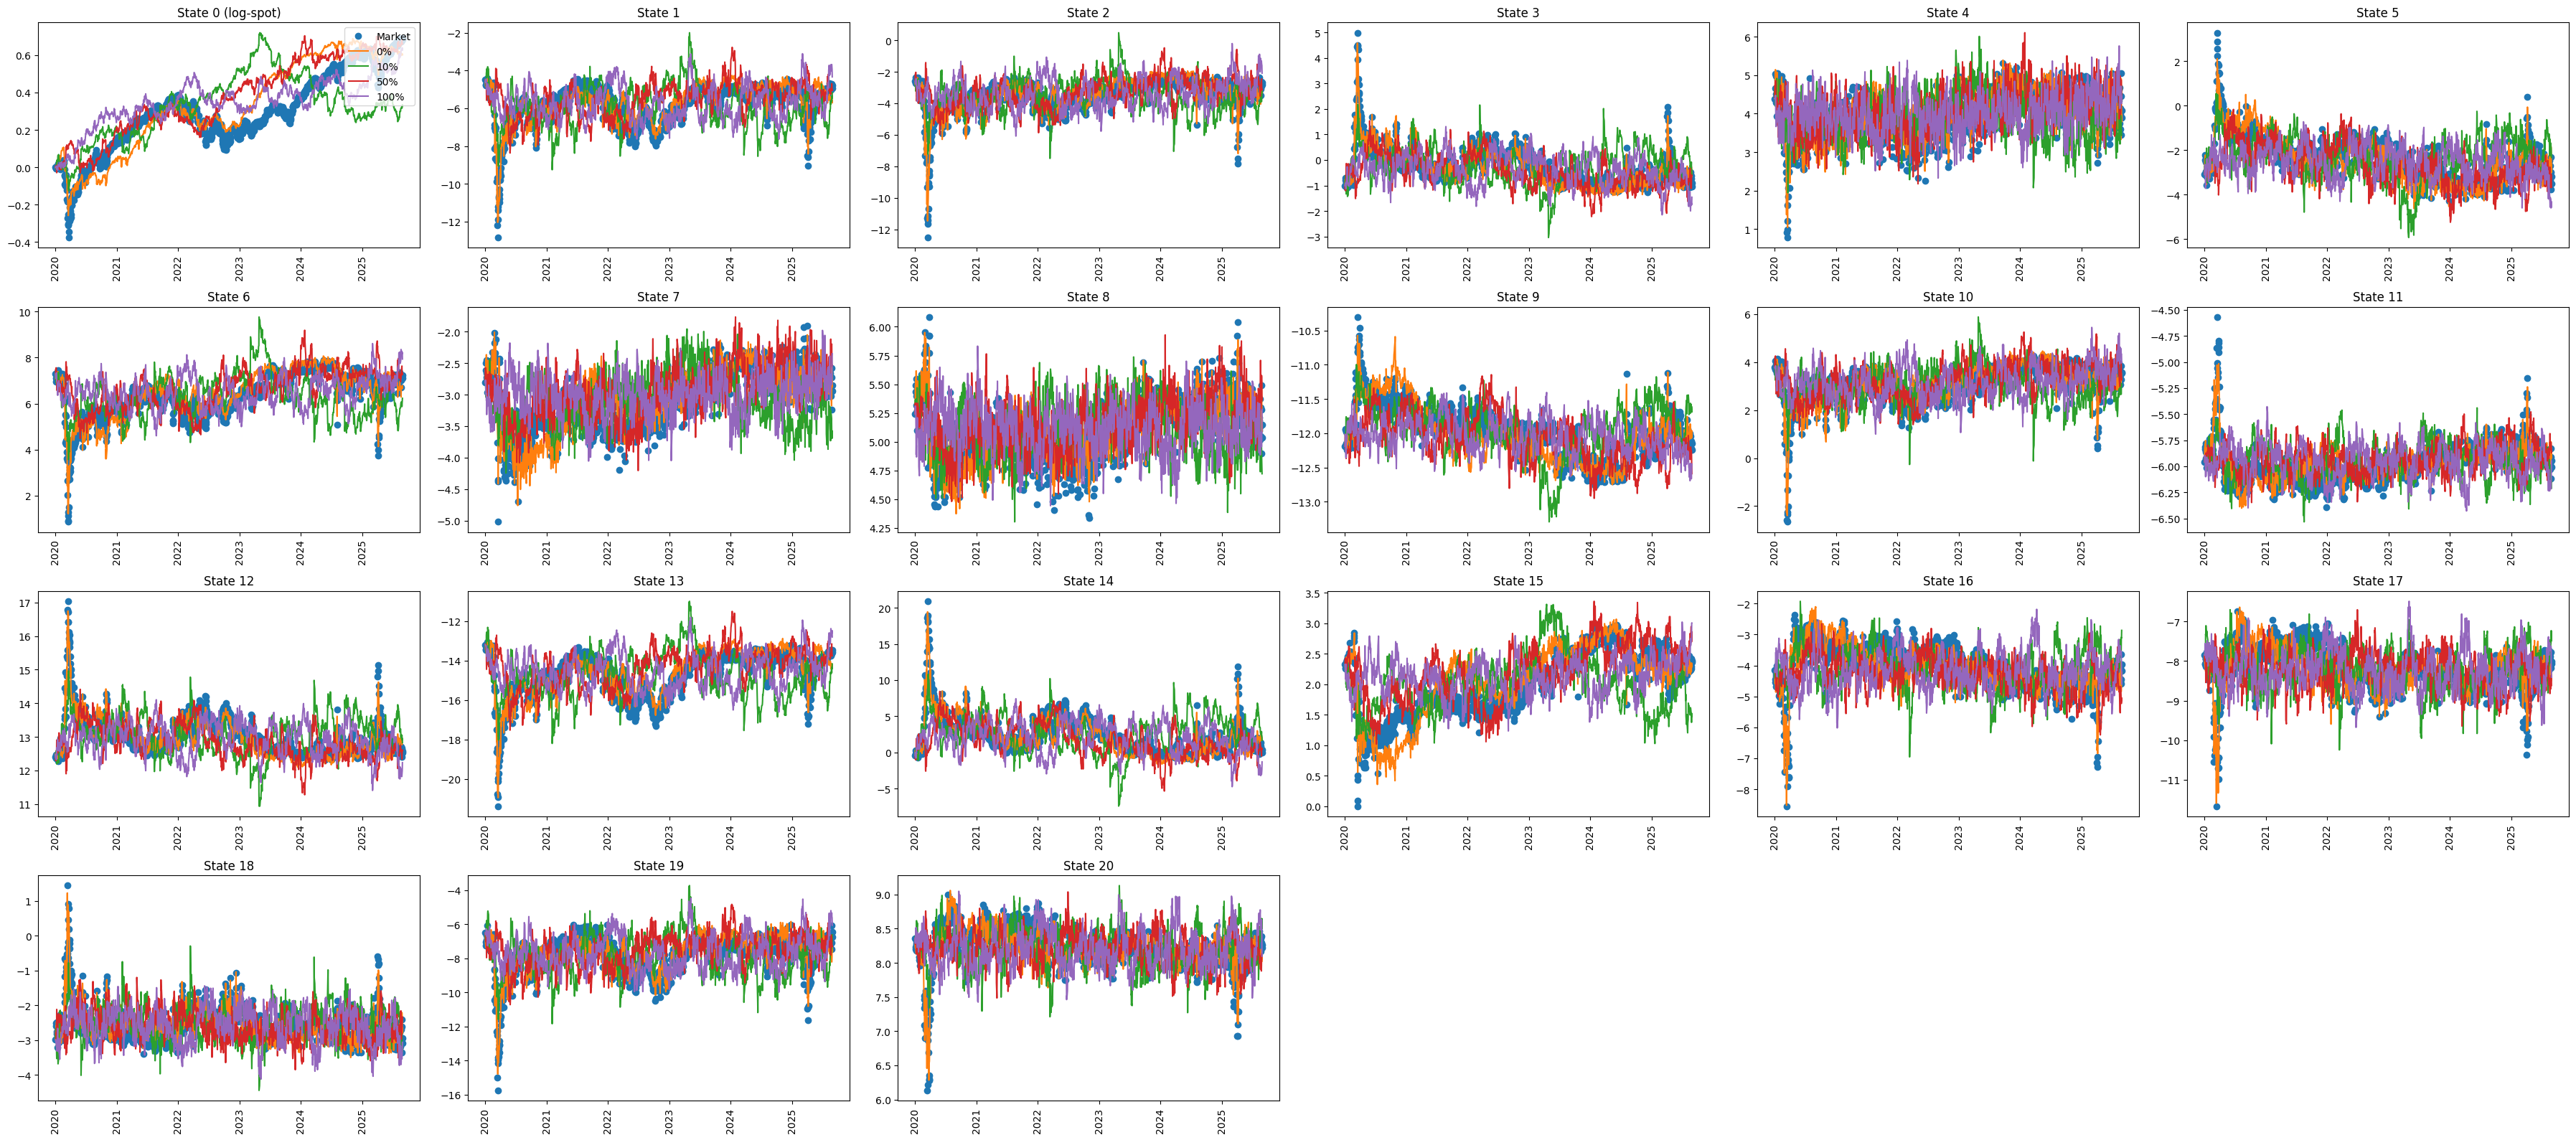

### ac_state20@sm25_100 0.2 factors

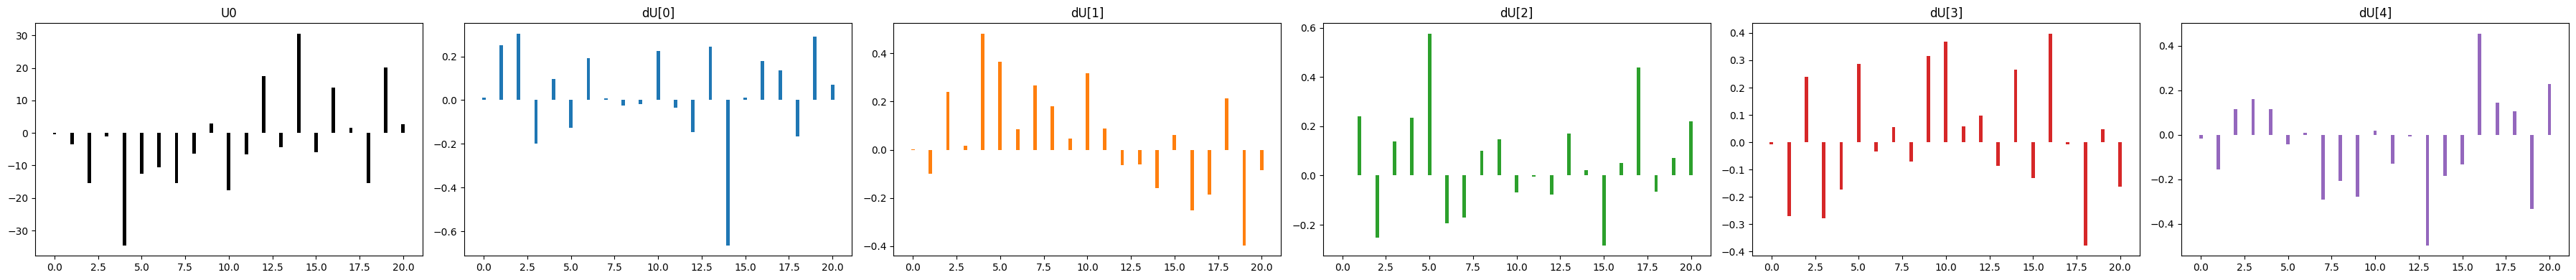

### ac_state20@sm25_100 0.2 weights

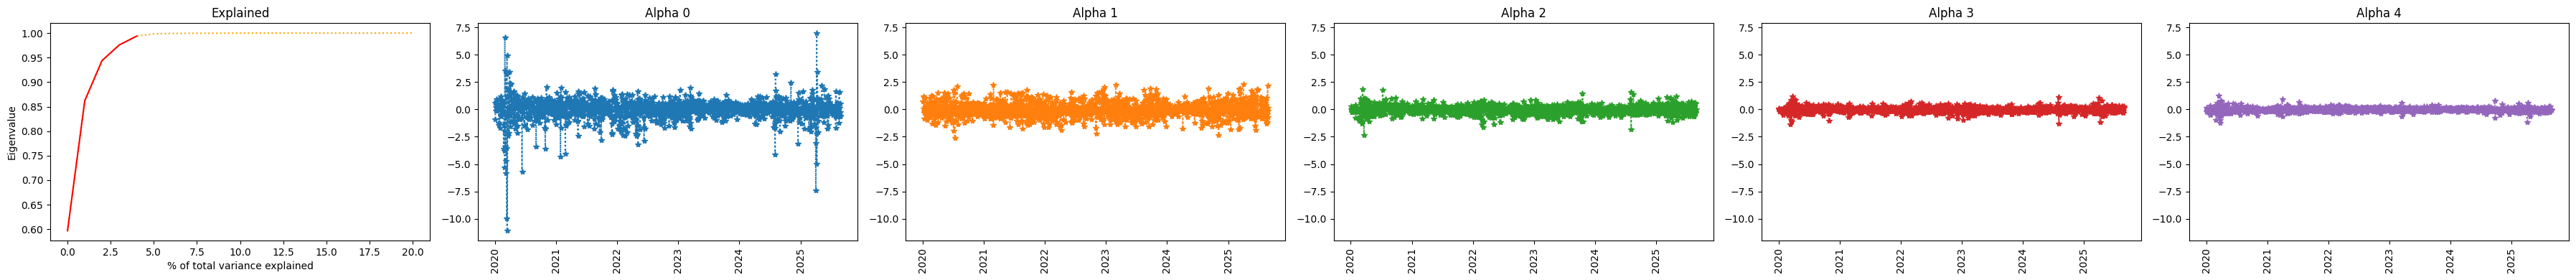

/done


In [3]:
from quantdata.dysanos.grid.torch_simulator import ARSamplerConfig, ARSampler, Context
from cdxcore.dynaplot import figure, colors_tableau, m_o_m
import numpy as np
from IPython.display import Markdown, display

ar_config      = ARSamplerConfig(num_alpha=5, use_matrix_exp=True)
sampler        = ARSampler( market, model, torch_data, config=ar_config, verbose=Context.all )

def plot(sampler):
    dates     = market.dates
    num_alpha = sampler.num_alpha

    with figure(row_size=4, col_size=6, columns=6 ) as fig:
        display(Markdown(f"## {model.qualified_label}: using {sampler.num_alpha} Alphas for {sampler.num_xstate} Extended States"))
        display(Markdown(f"### Real and simulated states, discrete to normal randomness"))

        r = sampler.pcaxar1
        xstate = sampler.xstate
        ndt    = r.ndt[:,None]
        dX     = ( r.U0 - sampler.xstate[:-1,:] @ r.k ) * ndt + r.alpha @ r.dU * np.sqrt(ndt)
        recX   = np.concatenate( [ sampler.xstate[:1,:], sampler.xstate[:1,:] + np.cumsum( dX, axis=0 ) ], axis=0 )
        assert recX.shape == xstate.shape, f"{recX.shape} != {xstate.shape}"

        rec        = np.zeros((len(dates), xstate.shape[1], 5))
        rec[...,0] = xstate
        rec[...,1] = sampler.hist_sample_xstates( index=0, num_steps=len(dates), num_samples=0, bandwidth=0., replay=True )
        rec[...,2] = sampler.hist_sample_xstates( index=0, num_steps=len(dates), num_samples=0, bandwidth=0.1, replay=False )
        rec[...,3] = sampler.hist_sample_xstates( index=0, num_steps=len(dates), num_samples=0, bandwidth=0.5, replay=False )
        rec[...,4] = sampler.hist_sample_xstates( index=0, num_steps=len(dates), num_samples=0, bandwidth=1., replay=False )

        labels = ["Market", "0%", "10%", "50%", "100%"]
        
        ax_ = None
        ax = fig.add_subplot(f"State 0 (log-spot)")
        for j in range(rec.shape[-1]):
            ax.plot( dates, rec[:,0,j], "o" if j==0 else "-", label=labels[j])
        ax.tick_params(axis="x", labelrotation=90)
        ax.legend(loc="upper right")
        for i in range(1,xstate.shape[1]):
            ax = fig.add_subplot(f"State {i}")
            for j, label in enumerate(labels):
                ax.plot( dates, rec[:,i,j], "o" if j==0 else "-", )
            ax.tick_params(axis="x", labelrotation=90)
    
    with figure(row_size=4, col_size=6, columns=6 ) as fig:
        display(Markdown(f"### {model.qualified_label} factors"))
        U0   = sampler.pcaxar1.U0
        dU   = sampler.pcaxar1.dU
        colors = colors_tableau()
        x    = np.arange(U0.shape[1])
        ax0  = fig.add_subplot("U0")
        ax0.bar( x, U0[0,:], width=0.2, color="black")
        for i in range( dU.shape[0] ):
            ax = fig.add_subplot(f"dU[{i}]")
            ax.bar( x, dU[i,:], width=0.2, color=next(colors))
            ax.sharex(ax0)
        ax0.set_ylim( m_o_m( U0, dU ) )
    
    with figure(row_size=4, col_size=6, columns=6 ) as fig:
        display(Markdown(f"### {model.qualified_label} weights"))
        mev = sampler.pcaxar1.vars_explained
        
        ax = fig.add_subplot("Explained")
        ax.plot( np.arange(0,len(mev)), mev, ":", color="orange", label="All")
        ax.plot( np.arange(0,num_alpha), mev[:num_alpha], "-", color="red",label=f"First {num_alpha}")
        ax.set_xlabel("% of total variance explained")
        ax.set_ylabel("Eigenvalue")
        
        ax_ = None
        colors = colors_tableau()
        alpha  = sampler.pcaxar1.alpha
        
        for i in range(alpha.shape[1]):
            ax = fig.add_subplot(f"Alpha {i}")
            ax.plot( dates[:-1], alpha[:,i], "*:", label="Model", color=next(colors))
            ax.tick_params(axis="x", labelrotation=90)
            if not ax_ is None:
                ax.sharey(ax_)
            else:
                ax_ = ax
        ax_.set_ylim( m_o_m(alpha) )

if True:
    plot(sampler)

print("/done")


## Simulate N steps


In [6]:
from cdxcore.util import fmt_big_byte_number
from quantdata.dysanos.grid.torch_pricer import SanosPricer
from quantdata.biz_calendar import DAYS_PER_YEAR
import torch
import numpy as np
from cdxcore.subdir import SubDir
from cdxcore.uniquehash import named_unique_filename48_8
import gc

from quantdata.dysanos.grid.torch_universe import create_universe

universe = None
gc.collect()

universe = create_universe( model=model, sampler=sampler, market=market, reset_rng=True, num_steps=10, num_samples=10_000, block_size=1000, bandwidth=0.2)
for k,v in universe.items():
    if v is None:
        continue
    if isinstance(v, np.ndarray):
        print( k, v.shape, v.nbytes, v.dtype, "ok" if np.all(np.isfinite(v)) else f"** {np.sum(np.isfinite(v))}")
    else:
        print( k, v )


00: Creating universe for ac_state20@sm25_100 0.2 of 10,000 samples over 10 time steps with a dt of 1.00d and a bandwidth of 0.2 with a blocksize of 1000: block 1/10; so far this took 0s... 

C:\Users\hans\OneDrive\Python3\quant_data\quantdata\dysanos\grid\torch_model.py:497: UserWarning: with_vols: transferring data to CPU


00: Created universe for ac_state20@sm25_100 0.2 of 10000 samples over 10 time steps in 10 blocks of size 1000 a dt of 1.00d and a bandwidth of 0.2: this took 1:57. Memory usage: 497.06MB bytes, which is 50.9KB bytes per sample.
C_t (10000, 9, 7, 20) 50400000 float32 ok
C_tp1 (10000, 9, 7, 20) 50400000 float32 ok
strikes_t (10000, 9, 7, 20) 50400000 float32 ok
strikes_tp1 (10000, 9, 7, 20) 50400000 float32 ok
spots (10000, 10) 400000 float32 ok
vols_t (10000, 9, 7, 20) 50400000 float32 ok
vols_tp1 (10000, 9, 7, 20) 50400000 float32 ok
delta_t (10000, 9, 7, 20) 50400000 float32 ok
vega_t (10000, 9, 7, 20) 50400000 float32 ok
gamma_t (10000, 9, 7, 20) 50400000 float32 ok
theta_t (10000, 9, 7, 20) 50400000 float32 ok
xstate (10000, 10, 21) 16800000 float64 ok
dt 0.003968253968253968
bandwidth 0.2
expiries (7,) 56 float64 ok


00: Solved dS measure change using 'entropy@1' on jax device cpu:0: success with status 'Optimization terminated successfully.'. Stats changed from 4.512 [2.902, 5.533] to -1.165e-06 [-5.457e-06, 5.526e-06]. This took 1.6s.
01:   dS stats changed from 4.512 [2.902, 5.533] to -1.165e-06 [-5.457e-06, 5.526e-06].
01:   dC stats changed from 5.73 [3.242, 7.827] to 1.461 [-0.01305, 3.589].


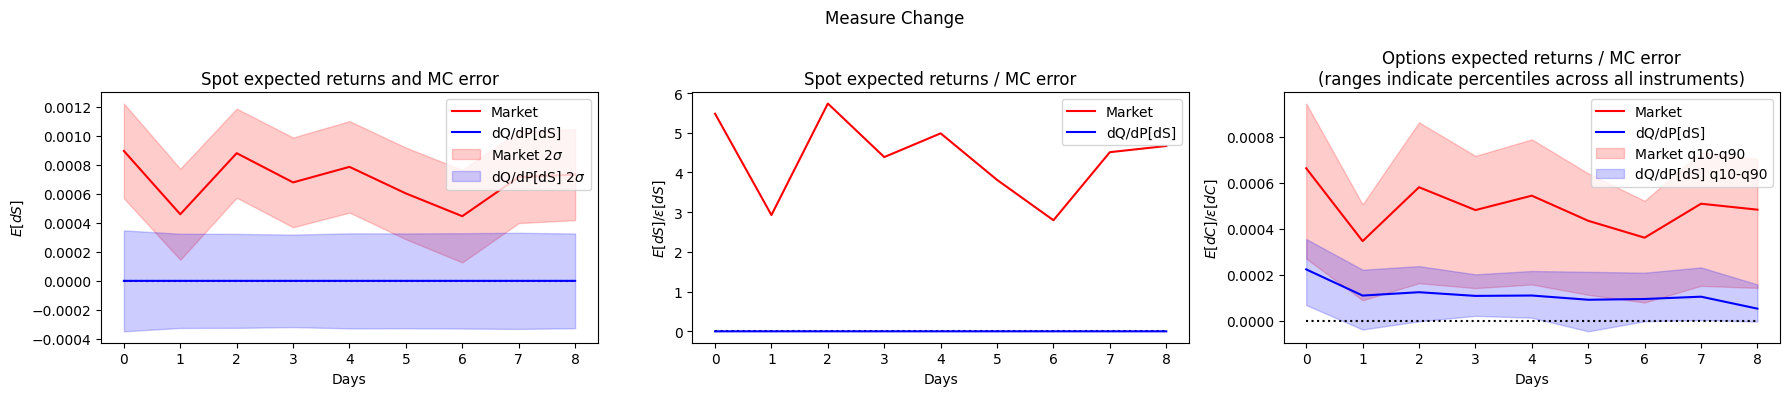

00: Found no option instruments with only positive or only negative returns. All will be used for the measure change optimization.
00: Found no delta-hedged option instruments with only positive or only negative returns. All will be used for the measure change optimization.


223

In [7]:
import math
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

from cdxcore.dynaplot import figure, colors_tableau, m_o_m
from cdxcore.err import verify_inp
from cdxcore.pretty import PrettyObject
from torch import mode
from collections.abc import Callable
from quantdata.biz_calendar import DAYS_PER_YEAR
import jax
jax.config.update("jax_enable_x64", True)        
from quantdata.jax.utility import jax_utility
import jax.numpy as jnp
import scipy
import warnings

def stats( X : np.ndarray, D : np.ndarray|None = None ) -> tuple[np.ndarray, np.ndarray]:
    """ Compute the mean and standard error of a 2D array X along axis=0. """
    assert X.shape[0] > 0, f"Expected X to have at least one row but got {X.shape}"
    assert D is None or D.shape == X.shape[:1], f"Expected D to have shape {X.shape[:1]} but got {D.shape}"

    D = D.reshape( (D.shape[0],) + (1,)*(X.ndim-1) ) if not D is None else 1.

    r = PrettyObject()
    r.mean = np.mean(D * X, axis=0)
    r.err  = np.sqrt(np.mean(D * (X - r.mean[None,...])**2, axis=0)) / np.sqrt(X.shape[0]) 
    r.dev  = np.where( r.err > 0., r.mean/np.where( r.err>0., r.err, 1.), 0.)

    # if we have more than two original dimensions -> per step stats
    if len(r.mean) > 1:
        mn = r.mean.reshape( r.mean.shape[0], -1 )
        r.mean_mean = np.mean(mn, axis=1)
        r.mean_q10,r.mean_med,r.mean_q90 = np.quantile(mn, [0.1, 0.5, 0.9], axis=1) 
        r.dev_mean = np.mean(mn, axis=1)
        r.dev_q10,r.dev_med,r.dev_q90 = np.quantile(mn, [0.1, 0.5, 0.9], axis=1) 

    # summary stats accross time
    r.total_q10, r.total_med, r.total_q90 = np.quantile( r.mean, [0.1, 0.5, 0.9] )
    r.tdev_q10, r.tdev_med, r.tdev_q90 = np.quantile( r.dev, [0.1, 0.5, 0.9] )
    r.info = f"{r.tdev_med:.4g} [{r.tdev_q10:.4g}, {r.tdev_q90:.4g}]"  # <- shows the percentiles of mean/err accross all instruments
    return r

class MeasureChange:
    
    def __init__(self, mode="powexp", lmbda=1.0, *, device = "cpu" ):
        r"""
        sup_a: E[ 1 - exp(-adS) ] = sup_a E[ - exp(-\sum_t a_t dS_t) + 1 ] = inf_a E[ exp(-\sum_t a_t dS_t) - 1 ]
        Optimal point:
        t: E[ - exp(-\sum_t a_t dS_t) dS_t ] = 0

        =>
        a* : 0 = E[dS] - a* E[dS^2] => a* = E[dS] / E[dS^2]
        """
        self.mode  = mode
        self.lmbda = lmbda
        self.u, self.deriv, self.u_label = jax_utility(mode, lmbda)
        self.device = jax.devices(device)[0] if isinstance(device, str) else device

        assert os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] == "false", f"Expected XLA_PYTHON_CLIENT_PREALLOCATE to be 'false' but got '{os.environ['XLA_PYTHON_CLIENT_PREALLOCATE']}'"

    def _solve(self, label, dX, prev_dQdP : np.ndarray|None = None, *, good_enough_dev = 1.0, verbose : Context = Context.all):
        """ Find a risk-neutral measure change dQ/dP for the given dX using the utility function specified by self.mode and self.lmbda. """
        assert len(dX.shape) == 2, f"Expected dX to be a 2D array but got {dX.shape}"
        assert prev_dQdP is None or prev_dQdP.shape == dX.shape[:1], f"Expected prev_dQdP to be a 1D array of shape {dX.shape[:1]} but got {prev_dQdP.shape}"

        if self.u_label == "id":
            return prev_dQdP
        P_stats = stats(dX, prev_dQdP)

        D    = prev_dQdP[:,None] if not prev_dQdP is None else 1.
        mean = np.mean(D*dX, axis=0)
        err  = np.sqrt(np.mean(D*(dX-mean[None,:])**2, axis=0)) / np.sqrt(dX.shape[0])
        dev  = np.abs( np.where( err>0., mean/np.where(err>0., err, 1.), 0.) )
        q99  = np.quantile( dev, 0.99 )
        max_ = np.max( dev )

        msg  = lambda : f"\rSolving for {label} measure change accross {dX.shape[1]} variables using '{self.u_label}'"

#        if q99 < 0.5:
#            verbose.write(lambda : f"{msg()}: skipping optimization because 99% of the deviations are only {q99:.4g}. P stats are {P_stats.info}.")
#            return prev_dQdP
        if max_ < good_enough_dev:
            verbose.write(lambda : f"{msg()}: skipping optimization because the maximum deviation is only {max_:.4g}. P stats are {P_stats.info}.")
            return prev_dQdP

        D = prev_dQdP if not prev_dQdP is None else 1.
        tme = verbose.timer()
        verbose.write(lambda : f"{msg()}: copying dX of shape {dX.shape} and size {fmt_big_byte_number(dX.nbytes)} to {self.device} (99% deviation {q99:.4g}, max deviation {max_:.4g})... ", end='')
        jdS = jax.device_put( dX.astype(np.float64), device=self.device )
        ay0 = jnp.zeros( (dX.shape[1]+1,), device=self.device, dtype=jdS.dtype )
    
        def objective( ay : jnp.array ):
            a = ay[1:]
            y = ay[0]
            X = jnp.sum( a[None,:]*jdS, axis=1)
            return -jnp.mean( D * (self.u(X+y)-y) )
        
        verbose.write(lambda : f"{msg()}: compiling objective; so far this took {tme}... ", end='')
        ff = jax.jit( objective ).lower( ay0 ).compile()
        def f(a):
            a = jax.device_put( a, device=self.device )
            return jax.device_get( ff(a) )

        verbose.write(lambda : f"{msg()}: compiling gradient; so far this took {tme}... ", end='')
        jacc = jax.jit( jax.grad(objective) ).lower( ay0 ).compile()
        def jac(a):
            a = jax.device_put( a, device=self.device )
            return jax.device_get( jacc(a) )

        verbose.write(lambda : f"{msg()}: running scipy optimizer; so far this took {tme}... ", end='')

        r   = scipy.optimize.minimize(  fun=f, 
                                        x0=ay0, 
                                        jac=jac, 
                                        method="BFGS", options={"disp": False, "gtol": 1e-8, "maxiter": 1000} )

        ok_msg = {"Desired error not necessarily achieved due to precision loss.",
                  "Maximum number of iterations has been exceeded."}
               
        if not r.success:
            if r.message not in ok_msg:
                raise RuntimeError(f"Solving for measure change using '{self.u_label}': scipy optimizer failed with message: '{r.message}'.")
            warnings.warn(f"Solving for measure change using '{self.u_label}': scipy optimizer failed with message: '{r.message}' -- continuing.")

        ax   = r.x[1:]
        yx   = r.x[0]
        X    = jnp.sum( ax[None,:]*jdS, axis=1)
        dQdP = self.deriv(X+yx)
        assert np.min( dQdP )>=-1E-6, f"Found negative dQdP {np.min( dQdP )}: {dQdP[dQdP<0.]}"
        dQdP = D * dQdP
        mean = np.mean(dQdP)
        if np.max( np.abs(mean)-1. )>1E-2:
            warnings.warn(f"dQdP does not sum up to 1 but {mean}. {f' Has prev_dQdP with {np.mean(prev_dQdP)}' if not prev_dQdP is None else ''}. yx={yx}, ax={ax}")
            return prev_dQdP if not prev_dQdP is None else dQdP

        assert np.max( np.abs(mean)-1. )<1E-2, f"dQdP does not sum up to 1 but {mean}.{f' Has prev_dQdP with {np.mean(prev_dQdP)}' if not prev_dQdP is None else ''}. yx={yx}, ax={ax}"
        dQdP = dQdP / mean
        assert np.all( np.isfinite(dQdP) ), f"Found non-finite dQdP: {dQdP}"
        Q_stats = stats(dX, dQdP)
        verbose.write(lambda : f"\rSolved {label} measure change using '{self.u_label}' on jax device {self.device}: success with status '{r.message}'. Stats changed from {P_stats.info} to {Q_stats.info}. This took {tme}." )
        return jax.device_get(dQdP)

    def solve( self, 
                dS, 
                dC : np.ndarray|None = None, *, 
                num_iter        = 10,
                good_enough_dev = 1.,
                num_bad         = 100,
                verbose : Context = Context.all ):
        """ Find a risk-neutral measure change dQ/dP for the given dX using the utility function specified by self.mode and self.lmbda. """
        assert len(dS.shape)==2, f"Expected dS to be a 2D array but got {dS.shape}"
        assert dC is None or ( dC.shape[:2] == dS.shape and len(dC.shape) == 4 ), f"Expected dC to be None or a 2D array of shape {dS.shape} but got {dC.shape}"
        if self.u_label == "id":
            return None
        
        dQdP_dS = self._solve("dS", dS, prev_dQdP=None, good_enough_dev=good_enough_dev, verbose=verbose)
        
        stats_S_0  = stats(dS, None)
        stats_C_0  = stats(dC, None) if not dC is None else None
        stats_S_t  = stats(dS, dQdP_dS)
        stats_C_t  = stats(dC, dQdP_dS) if not dC is None else None
        verbose.report(1,f"dS stats changed from {stats_S_0.info} to {stats_S_t.info}.")
        verbose.report(1,f"dC stats changed from {stats_C_0.info} to {stats_C_t.info}.") if not dC is None else None

        fig = figure("Measure Change", row_size=4, col_size=6, columns=None )
        store = fig.store()
        ax_ret  = fig.add_subplot("Spot expected returns and MC error")
        ax_spot = fig.add_subplot("Spot expected returns / MC error")
        ax_opt  = fig.add_subplot("Options expected returns / MC error\n(ranges indicate percentiles across all instruments)") if not dC is None else None
        x_ax    = np.arange(dS.shape[1], dtype=float)
        ax_ret.set_xlabel("Days")
        ax_ret.set_ylabel(r"$E[dS]$")
        ax_spot.set_xlabel("Days")
        ax_spot.set_ylabel(r"$E[dS] / \epsilon[dS]$")
        ax_ret.plot( x_ax, x_ax*0., ":", color="black" )
        ax_spot.plot( x_ax, x_ax*0., ":", color="black" )

        ax_ret.plot( x_ax, stats_S_0.mean, "-", color="red", label="Market" )
        ax_ret.plot( x_ax, stats_S_t.mean, "-", color="blue", label="dQ/dP[dS]" )
        ax_ret.fill_between( x_ax, stats_S_0.mean-2*stats_S_0.err, stats_S_0.mean+2*stats_S_0.err, color="red", alpha=0.2, label=r"Market 2$\sigma$" )
        ax_ret.fill_between( x_ax, stats_S_t.mean-2*stats_S_t.err, stats_S_t.mean+2*stats_S_t.err, color="blue", alpha=0.2, label=r"dQ/dP[dS] 2$\sigma$" )
        ax_spot.plot( x_ax, stats_S_0.dev, "-", color="red", label="Market" )
        ax_spot.plot( x_ax, stats_S_t.dev, "-", color="blue", label="dQ/dP[dS]" )

        if not dC is None:
            ax_opt.set_xlabel("Days")
            ax_opt.set_ylabel(r"$E[dC] / \epsilon[dC]$")
            ax_opt.plot( x_ax, x_ax*0., ":", color="black" )
            ax_opt.plot( x_ax, stats_C_0.dev_mean, "-", color="red", label="Market" )
            ax_opt.plot( x_ax, stats_C_t.dev_mean, "-", color="blue", label="dQ/dP[dS]" )
            ax_opt.fill_between( x_ax, stats_C_0.dev_q10, stats_C_0.dev_q90, color="red", alpha=0.2, label="Market q10-q90" )
            ax_opt.fill_between( x_ax, stats_C_t.dev_q10, stats_C_t.dev_q90, color="blue", alpha=0.2, label="dQ/dP[dS] q10-q90" )
            store += ax_opt.legend(loc="upper right")

        ax_ret.legend(loc="upper right")
        store += ax_spot.legend(loc="upper right")

        fig.render()
        if dC is None:
            fig.close()
            return dQdP_dS

        fig.close()
        return dQdP_dS
    
        with verbose.write_t(lambda : f"Finding deterministic measure change for dS and dC:") as tme:
            verbose1 = verbose(1)
            dQdP = self._solve("dS", dS, prev_dQdP=None, good_enough_dev=good_enough_dev, verbose=verbose1)

            for itr in range(num_iter):
                dC_flat  = dC.reshape(dC.shape[0], -1)
                stats_C  = stats(dC_flat, dQdP)
                abs_dev  = np.abs( stats_C.dev )
                ixs      = np.argsort( abs_dev )
                dCbad    = dC_flat[:,ixs]
                abs_dev  = abs_dev[ixs]
                del ixs 

                ixbad    = np.searchsorted( abs_dev, good_enough_dev, side="left")+1
                if ixbad >= len(abs_dev):
                    verbose.write(lambda : f"\rIncrement {itr+1}/{num_iter}: top {num_bad} instruments have deviation {abs_dev[ixbad][0]:.4g}. Stats are {stats_C.info}. This took {tme}.")
                    break
                ixbad    = max(ixbad, len(abs_dev)-num_bad)
                dCbad    = dCbad[:,ixbad:]
                abs_dev  = abs_dev[ixbad:]

                verbose.write(lambda : f"\rIncrement {itr+1}/{num_iter}: top drift {len(abs_dev)} instruments have abs deviation {abs_dev[0]:.4g} to {abs_dev[-1]:.4g}. Overall stats are {stats_C.info}. This took {tme}.")

                label   = f"dC {(itr+1)/num_iter:.0%}"
                dQdP    = self._solve(label, dCbad, prev_dQdP=dQdP, verbose=verbose1)
                                           
                stats_S_tp1 = stats(dS, dQdP)
                stats_C_tp1 = stats(dC, dQdP)
                verbose.report(1,f"dS stats changed from {stats_S_0.info} to {stats_S_tp1.info}.\n"+\
                                 f"dC stats changed from {stats_C_0.info} to {stats_C_tp1.info}.")

                store.clear()
                store += ax_spot.plot( x_ax, stats_S_tp1.dev, label=f"dQ/dP") 
                store += ax_opt.plot( x_ax, stats_C_tp1.dev_mean, label=f"dQ/dP")
                store += ax_opt.fill_between( x_ax, stats_C_tp1.dev_q10, stats_C_tp1.dev_q90, alpha=0.2, label=f"dQ/dP q10-q90")
                ax_spot.legend(loc="upper right")
                ax_opt.legend(loc="upper right")
                fig.render()

                stats_S_t = stats_S_tp1
                stats_C_t = stats_C_tp1
        fig.close()
        return dQdP


def change(universe, samples : int = 4, seed : int = 123456789, ntau_head=2, ntau_tail=2, verbose:Context=Context.all):

    spots    = universe["spots"]
    C_t      = universe["C_t"]
    C_tp1    = universe["C_tp1"]
    vols_t   = universe["vols_t"]
    vols_tp1 = universe["vols_tp1"]
    expiries = universe["expiries"]
    strikes_t = universe["strikes_t"]
    strikes_tp1 = universe["strikes_tp1"]
    delta_t = universe["delta_t"]

    S, TAU   = universe["spots"].shape
    T, N     = universe["vols_t"].shape[2:]
    dt       = universe['dt']
    time_d   = np.arange(TAU,dtype=float) * dt * DAYS_PER_YEAR

    np.random.seed(seed)
    samples = sorted( np.random.randint(0, S, size=samples) ) if isinstance(samples, int) else list(samples)

    dC           = C_tp1 - C_t
    dS           = spots[:,1:] - spots[:,:-1]
    delta_hedged = dC - delta_t * dS[:,:,None,None]

    ms_dC = MeasureChange("entropy")
    dQdP  = ms_dC.solve( dS, dC, verbose=verbose )

    def test_arb(label, dC):
        max_ret_dC = np.max( dC, axis=0 )
        min_ret_dC = np.min( dC, axis=0 )

        static_up  = ( max_ret_dC >= min_ret_dC ) & ( min_ret_dC >= 0. )
        static_dn  = ( max_ret_dC <= min_ret_dC ) & ( max_ret_dC <= 0. )
        ignore     = None
        if np.any(static_up) or np.any(static_dn):
            s = ""
            n_total = dC.shape[1]*dC.shape[2]*dC.shape[3]
            if np.any(static_up):
                s = f"Found {np.sum(static_up)}/{n_total} {label} instruments with only positive returns"
            if np.any(static_dn):
                if s == "":
                    s = f"Found {np.sum(static_dn)}/{n_total} {label} instruments with only negative returns"
                else:
                    s += f" and {np.sum(static_dn)}/{n_total} {label} instruments with only negative returns"

            verbose.write(lambda : f"Warning: {s}. These instruments will be ignored for the measure change optimization.")
            ignore = static_up | static_dn
        else:
            verbose.write(lambda : f"Found no {label} instruments with only positive or only negative returns. All will be used for the measure change optimization.")

    test_arb("option", dC)
    test_arb("delta-hedged option", delta_hedged)

    return dQdP

dQdP_dS = change(universe, samples=4, seed=123456789, ntau_head=2, ntau_tail=2)
gc.collect()

## Torch Deep Hedging

00: Training small version 0.1 group 'deephedging' for 10000000 epochs.
00: Using all samples with learning rate 0.01 and weight decay 0.0001.
00: Copied 7 arrays with a total size 159.07MB to Env(prec=32,device=cpu,debug=False). This took 0.059s.                           
00: Instantiating small version 0.1 on Env(prec=32,device=cpu,debug=False)... done; this took 0.526ms.
00: Using recovery checkpoint 'C:/users/public/.dysanos_dh/deephedging/small 5d114829.pt'.
00: Initial loss is -0. This took 0.15s.


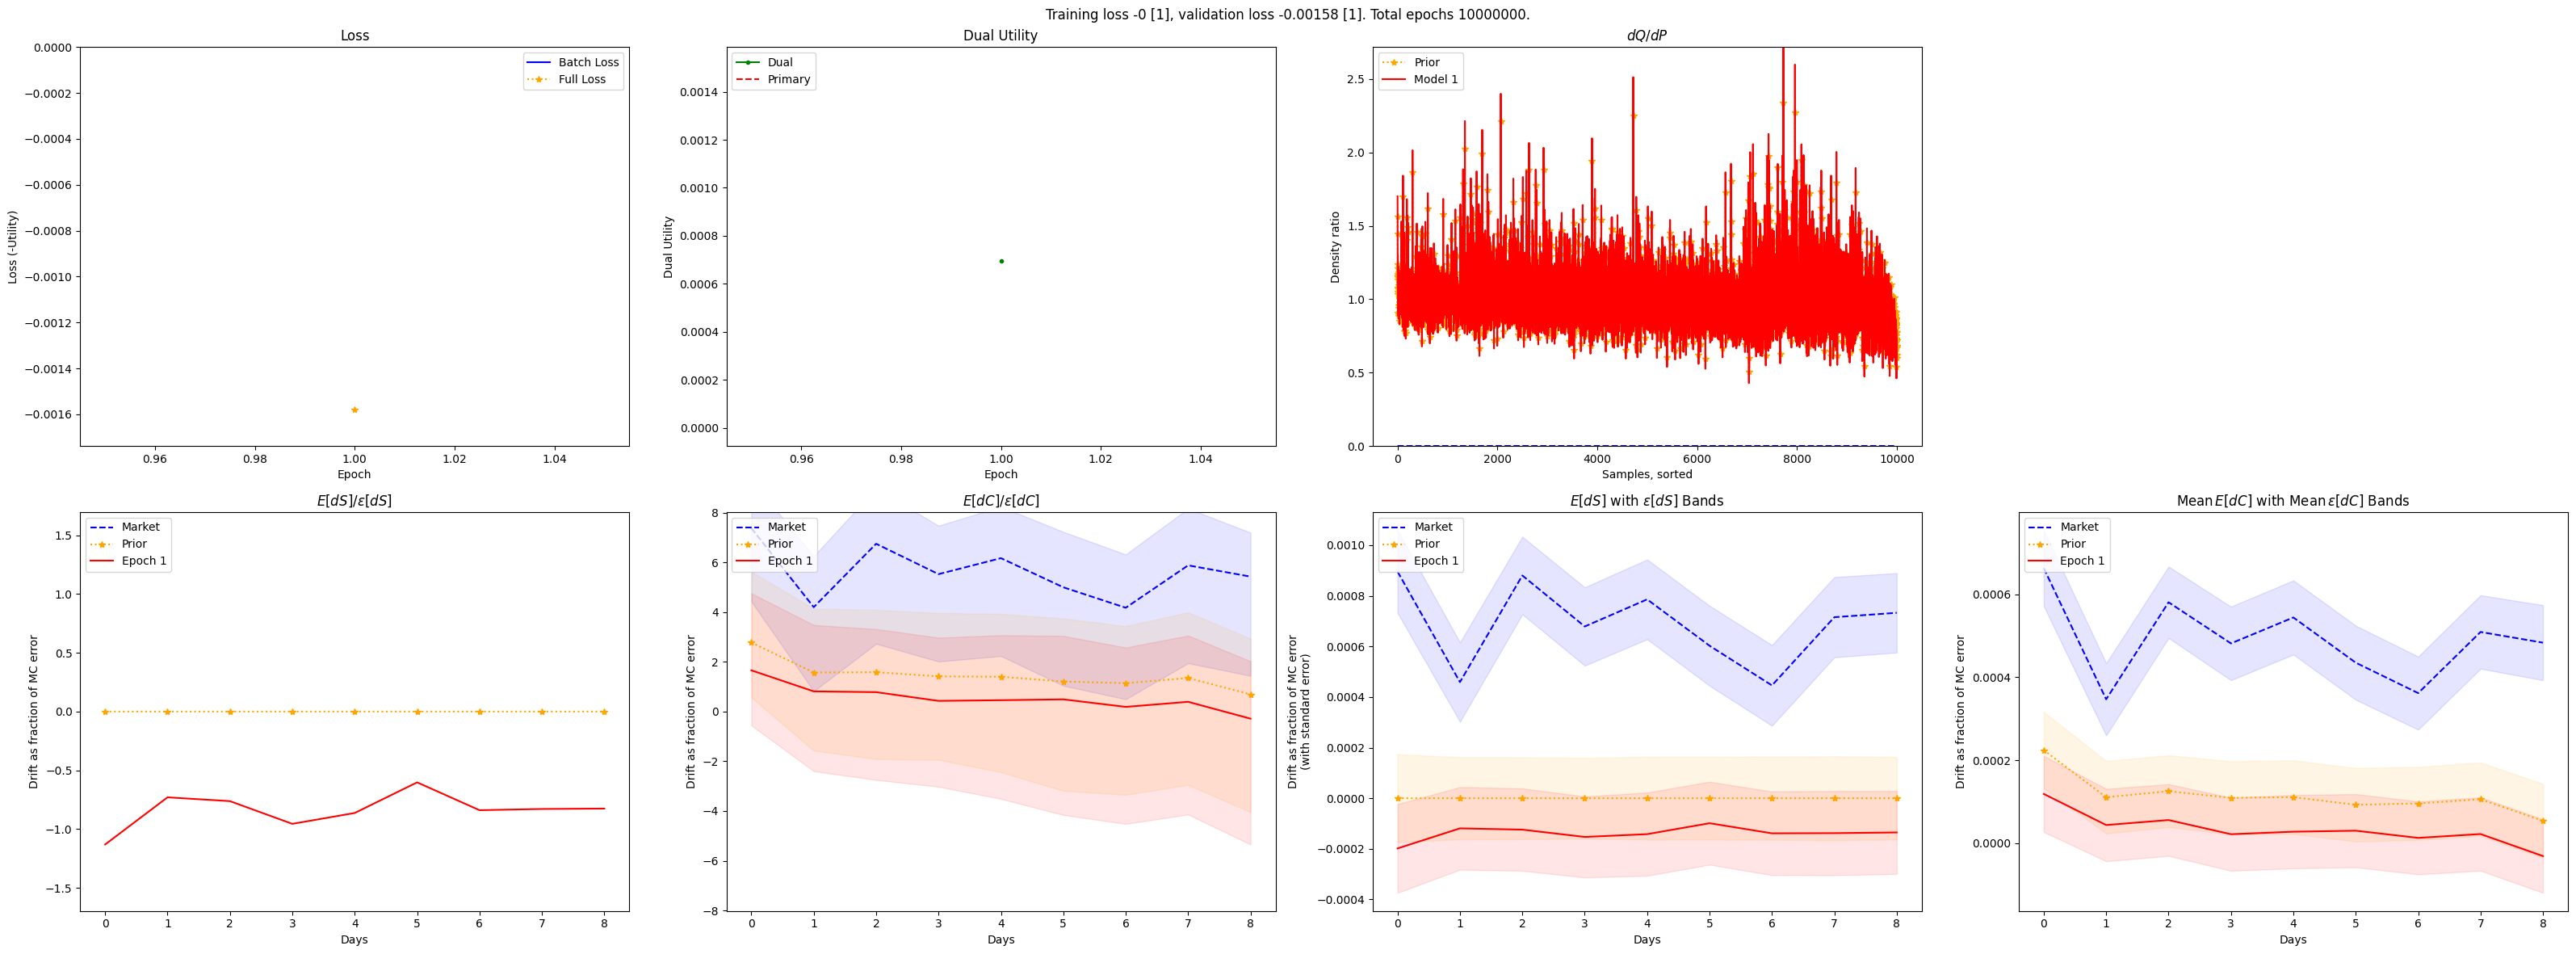

00: Training small@deephedging 0.1 with epochs=10000000,lr=0.01->1e-06,wdec=0.0001,bsize=all on Env(prec=32,device=cpu,debug=False):
01:   Epoch 150/10000000, Loss: -0.1522. So far this took 12s.                                        

In [ ]:
import importlib as imp
import quantdata.dysanos.grid.torch_drift_change as _
imp.reload(_)

from quantdata.dysanos.grid.torch_drift_change import DualRiskNeutralDeepHedgingConfig, FeedForwardConfig, train, TrainConfig, VizConfig

mdl_config = DualRiskNeutralDeepHedgingConfig( 
    label="small",#"per_step_fixed 1_2", 
    group="deephedging", 
    user_version="0.1", 
    utility="entropy", 
    lmnda=1.0, 
    delta_hedged=False, 
    dual_weight=0.1,
    spot_only=False,
    per_step="fixed",
    cost = 1E-6,
    action_config=FeedForwardConfig(
        num_depth = 1,
        num_width = 2,
        activation = "SELU",
        use_bias = True
    ),
    _debug_no_xstate = True,
    _debug_ignore_prior = False,
    _debug_do_not_normalize_dQdP = False
)

import gc
gc.collect()


gpu_id = 0
device = torch.device(f"cuda:{gpu_id}" if torch.cuda.is_available() else "cpu")

def run():
    trn_config = TrainConfig( num_epochs=1_000_0000, lr=1E-2, final_lr=1E-6, weight_decay=1e-4, batch_size=None, compile=False, epoch_interval=100 )
    viz_config = VizConfig()
    model = train( universe, sampler, ref_dQdP=dQdP_dS, mdl_config=mdl_config, trn_config=trn_config, viz_config=viz_config, restart=False, just_load="no", env=BaseEnvironment(), verbose=Context.all )
    gc.collect()

model_output = run()